# Evaluation and Comparison of Examination Timetabling Algorithms

## Objective

This notebook evaluates and compares the graph-colouring and adaptive heuristic approaches developed for the University of Nottingham examination timetabling benchmark.

## Algorithms Evaluated

1. Greedy colouring — alphabetical order
2. Welsh–Powell
3. DSATUR
4. Adaptive v1
5. Adaptive v2
6. Adaptive v3 — spacing-aware colour-order optimization

## Evaluation Metrics

- Number of periods used
- Number of graph conflict violations
- Same-day adjacent-exam penalty
- Validity and completeness of the generated schedule

## Research Goal

Determine how the proposed adaptive heuristics compare with established graph-colouring baselines in terms of timetable compactness and the proposed spacing metric.

In [14]:
from pathlib import Path
import pickle
import networkx as nx
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()

graph_path = PROJECT_ROOT / "data" / "processed" / "conflict_graph.gpickle"

with open(graph_path, "rb") as file:
    G = pickle.load(file)

print("Number of exams:", G.number_of_nodes())
print("Number of conflict edges:", G.number_of_edges())

Number of exams: 800
Number of conflict edges: 9990


In [15]:
# Record the results obtained in Notebook 04.
results = [
    {
        "Algorithm": "Greedy (Alphabetical)",
        "Periods": 25,
        "Conflict Violations": 0,
    },
    {
        "Algorithm": "Welsh–Powell",
        "Periods": 18,
        "Conflict Violations": 0,
    },
    {
        "Algorithm": "DSATUR",
        "Periods": 17,
        "Conflict Violations": 0,
    },
    {
        "Algorithm": "Adaptive v1",
        "Periods": 17,
        "Conflict Violations": 0,
    },
    {
        "Algorithm": "Adaptive v2",
        "Periods": 18,
        "Conflict Violations": 0,
    },
    {
        "Algorithm": "Adaptive v3",
        "Periods": 17,
        "Conflict Violations": 0,
    },
]

results_df = pd.DataFrame(results)

results_df

,Algorithm,Periods,Conflict Violations
0,Greedy (Alphabetical),25,0
1,Welsh–Powell,18,0
2,DSATUR,17,0
3,Adaptive v1,17,0
4,Adaptive v2,18,0
5,Adaptive v3,17,0


In [16]:
# Add the measured spacing penalties from Notebook 04.
spacing_penalties = {
    "Greedy (Alphabetical)": None,
    "Welsh–Powell": None,
    "DSATUR": 8630,
    "Adaptive v1": 8576,
    "Adaptive v2": 8716,
    "Adaptive v3": 974,
}

results_df["Same-Day Adjacent-Exam Penalty"] = (
    results_df["Algorithm"].map(spacing_penalties)
)

results_df

,Algorithm,Periods,Conflict Violations,Same-Day Adjacent-Exam Penalty
0,Greedy (Alphabetical),25,0,NaN
1,Welsh–Powell,18,0,NaN
2,DSATUR,17,0,8630.0
3,Adaptive v1,17,0,8576.0
4,Adaptive v2,18,0,8716.0
5,Adaptive v3,17,0,974.0


In [17]:
# Compare each recorded spacing penalty with the DSATUR baseline.
baseline_penalty = spacing_penalties["DSATUR"]

results_df["Penalty Reduction (%)"] = results_df[
    "Same-Day Adjacent-Exam Penalty"
].apply(
    lambda penalty: (
        round((baseline_penalty - penalty) / baseline_penalty * 100, 2)
        if pd.notna(penalty)
        else None
    )
)

results_df

,Algorithm,Periods,Conflict Violations,Same-Day Adjacent-Exam Penalty,Penalty Reduction (%)
0,Greedy (Alphabetical),25,0,NaN,NaN
1,Welsh–Powell,18,0,NaN,NaN
2,DSATUR,17,0,8630.0,0.00
3,Adaptive v1,17,0,8576.0,0.63
4,Adaptive v2,18,0,8716.0,-1.00
5,Adaptive v3,17,0,974.0,88.71


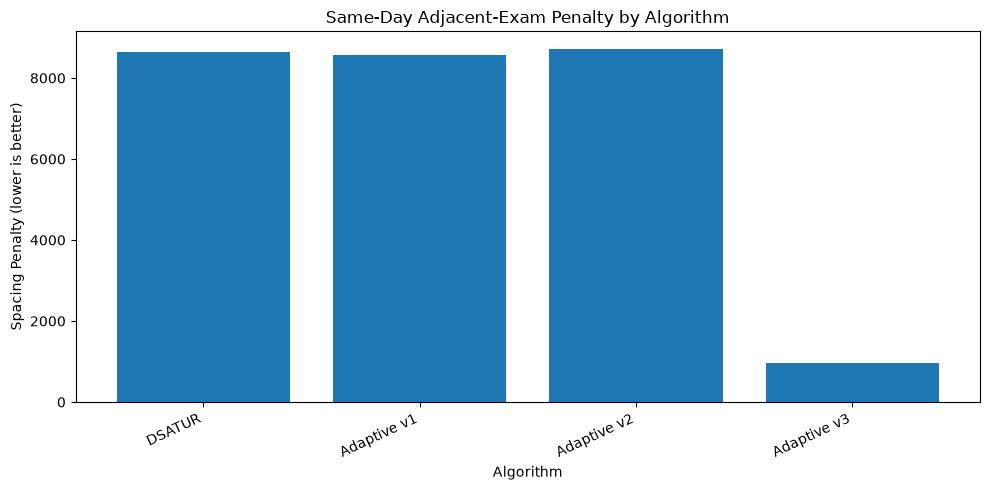

In [18]:
import matplotlib.pyplot as plt

plot_df = results_df.dropna(
    subset=["Same-Day Adjacent-Exam Penalty"]
)

plt.figure(figsize=(10, 5))
plt.bar(
    plot_df["Algorithm"],
    plot_df["Same-Day Adjacent-Exam Penalty"],
)
plt.title("Same-Day Adjacent-Exam Penalty by Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Spacing Penalty (lower is better)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Results and Discussion

### Comparison of Algorithms

The initial evaluation compares six graph-colouring approaches using the number of periods, graph conflict violations, and the proposed same-day adjacent-exam penalty.

DSATUR achieved a timetable using 17 periods with zero graph conflict violations. Adaptive v1 also used 17 periods and produced a slightly lower spacing penalty, decreasing it from 8,630 to 8,576 (0.63%). Adaptive v2 used 18 periods and recorded a penalty of 8,716, which was higher than the DSATUR baseline.

Adaptive v3 used 17 periods and recorded a penalty of 974. Compared with DSATUR, this represents an 88.71% reduction in the proposed spacing penalty without increasing the number of periods. This result suggests that reordering colour classes can substantially improve this spacing measure while preserving graph-colouring validity.

### Limitations

The spacing penalty is a proposed research metric and should not be interpreted as the official benchmark objective. Spacing scores for Greedy (Alphabetical) and Welsh–Powell have not yet been calculated. Furthermore, zero graph conflict violations do not establish that every official benchmark constraint is satisfied. Date and time restrictions, precedence requirements, spread-out constraints, and room availability require separate implementation and validation.

### Conclusion

Among the approaches evaluated so far, Adaptive v3 achieved the lowest measured spacing penalty while using the same number of periods as DSATUR and maintaining zero graph conflict violations. Further validation against the complete benchmark constraints is required before drawing conclusions about overall timetable quality.

In [19]:
# Audit whether the exams mentioned in selected benchmark constraints
# exist in the conflict graph and the current schedule.

benchmark_exam_groups = {
    "Fixed-date / date-window": [
        "F321Q6E1", "F321T6E1",
        "H21M01E1", "H22M02E1", "H2CM04E1",
        "G13RE2E1",
    ],
    "Morning restrictions": [
        "K1AHWAE2", "H63122E1",
    ],
    "Thursday afternoon": [
        "V13101E1",
    ],
    "Precedence": [
        "F13P03E1", "F13X03E1",
        "F13P05E1", "F13X04E1",
    ],
    "Immediate succession": [
        "H3BFM2E1", "H3BFM2E2",
    ],
    "Different times": [
        "H8B040E1", "H8C001E1",
    ],
}

scheduled_exam_ids = set(
    results_df["Algorithm"].dropna()
)

# Use the actual exam IDs from the graph and the current v3 schedule.
scheduled_exam_ids = set(G.nodes())

audit_rows = []

for constraint_group, exam_ids in benchmark_exam_groups.items():
    for exam_id in exam_ids:
        audit_rows.append({
            "Constraint group": constraint_group,
            "Exam ID": exam_id,
            "In conflict graph": exam_id in G,
        })

constraint_audit_df = pd.DataFrame(audit_rows)
constraint_audit_df

,Constraint group,Exam ID,In conflict graph
0,Fixed-date / date-window,F321Q6E1,True
1,Fixed-date / date-window,F321T6E1,True
2,Fixed-date / date-window,H21M01E1,True
3,Fixed-date / date-window,H22M02E1,True
4,Fixed-date / date-window,H2CM04E1,True
5,Fixed-date / date-window,G13RE2E1,True
6,Morning restrictions,K1AHWAE2,True
7,Morning restrictions,H63122E1,True
8,Thursday afternoon,V13101E1,True
9,Precedence,F13P03E1,True


In [20]:
schedule = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "adaptive_v3_schedule.csv"
)

schedule["date"] = pd.to_datetime(schedule["date"])

print("Scheduled exams:", len(schedule))
print("Unique exams:", schedule["exam_id"].nunique())
print("Periods used:", schedule["period_index"].nunique())

Scheduled exams: 800
Unique exams: 800
Periods used: 17


In [21]:
schedule_lookup = schedule.set_index("exam_id")

date_rules = {
    "F321Q6E1": ("exact", "1995-01-27"),
    "F321T6E1": ("exact", "1995-01-30"),
    "H21M01E1": ("range", "1995-01-23", "1995-01-24"),
    "H22M02E1": ("range", "1995-01-23", "1995-01-24"),
    "H2CM04E1": ("range", "1995-01-23", "1995-01-24"),
    "G13RE2E1": ("before", "1995-01-30"),
}

date_check_rows = []

for exam_id, rule in date_rules.items():
    exam_date = pd.to_datetime(schedule_lookup.loc[exam_id, "date"])

    if rule[0] == "exact":
        valid = exam_date == pd.Timestamp(rule[1])
        requirement = f"Must be on {rule[1]}"

    elif rule[0] == "range":
        valid = pd.Timestamp(rule[1]) <= exam_date <= pd.Timestamp(rule[2])
        requirement = f"Must be between {rule[1]} and {rule[2]}"

    else:
        valid = exam_date < pd.Timestamp(rule[1])
        requirement = f"Must be before {rule[1]}"

    date_check_rows.append({
        "Exam ID": exam_id,
        "Scheduled date": exam_date.date(),
        "Requirement": requirement,
        "Pass": valid,
    })

date_check_df = pd.DataFrame(date_check_rows)
date_check_df

,Exam ID,Scheduled date,Requirement,Pass
0,F321Q6E1,1995-01-23,Must be on 1995-01-27,False
1,F321T6E1,1995-01-28,Must be on 1995-01-30,False
2,H21M01E1,1995-01-30,Must be between 1995-01-23 and 1995-01-24,False
3,H22M02E1,1995-01-23,Must be between 1995-01-23 and 1995-01-24,True
4,H2CM04E1,1995-01-26,Must be between 1995-01-23 and 1995-01-24,False
5,G13RE2E1,1995-01-26,Must be before 1995-01-30,True


In [22]:
date_check_df = date_check_df.merge(
    schedule[["exam_id", "period_index", "time"]],
    left_on="Exam ID",
    right_on="exam_id",
    how="left"
).drop(columns=["exam_id"])

date_check_df[
    ["Exam ID", "Scheduled date", "time", "period_index", "Requirement", "Pass"]
]

,Exam ID,Scheduled date,time,period_index,Requirement,Pass
0,F321Q6E1,1995-01-23,16:30,2,Must be on 1995-01-27,False
1,F321T6E1,1995-01-28,09:00,15,Must be on 1995-01-30,False
2,H21M01E1,1995-01-30,09:00,16,Must be between 1995-01-23 and 1995-01-24,False
3,H22M02E1,1995-01-23,16:30,2,Must be between 1995-01-23 and 1995-01-24,True
4,H2CM04E1,1995-01-26,16:30,11,Must be between 1995-01-23 and 1995-01-24,False
5,G13RE2E1,1995-01-26,09:00,9,Must be before 1995-01-30,True


In [24]:
from datetime import date, timedelta

period_rows = []
period_index = 0
current_date = date(1995, 1, 23)
last_date = date(1995, 2, 4)

while current_date <= last_date:
    if current_date.weekday() < 5:
        times = ["09:00", "13:30", "16:30"]
    elif current_date.weekday() == 5:
        times = ["09:00"]
    else:
        times = []

    for exam_time in times:
        period_rows.append({
            "period_index": period_index,
            "date": pd.Timestamp(current_date),
            "day": current_date.strftime("%A"),
            "time": exam_time,
        })
        period_index += 1

    current_date += timedelta(days=1)

periods_df = pd.DataFrame(period_rows)

print("Available benchmark periods:", len(periods_df))

Available benchmark periods: 32


In [25]:
fixed_schedule = schedule.copy()

date_assignments = {
    "F321Q6E1": ("1995-01-27", "09:00"),
    "F321T6E1": ("1995-01-30", "09:00"),
    "H21M01E1": ("1995-01-23", "09:00"),
    "H22M02E1": ("1995-01-23", "13:30"),
    "H2CM04E1": ("1995-01-24", "09:00"),
}

period_lookup = periods_df.copy()
period_lookup["date"] = pd.to_datetime(period_lookup["date"])

for exam_id, (date, time) in date_assignments.items():
    matching_periods = period_lookup[
        (period_lookup["date"] == pd.Timestamp(date))
        & (period_lookup["time"] == time)
    ]

    if matching_periods.empty:
        print(f"No valid period found for {exam_id}")
        continue

    period_index = matching_periods.iloc[0]["period_index"]

    fixed_schedule.loc[
        fixed_schedule["exam_id"] == exam_id,
        ["date", "time", "period_index"]
    ] = [pd.Timestamp(date), time, period_index]

fixed_schedule

,exam_id,period_index,date,time
0,LKA1FAE1,12,1995-01-27,09:00
1,LK10SAE1,2,1995-01-23,16:30
2,L81122E1,5,1995-01-24,16:30
3,N1A110E1,9,1995-01-26,09:00
4,C81ICAE1,6,1995-01-25,09:00
...,...,...,...,...
795,F12X04E2,12,1995-01-27,09:00
796,F12X04E3,12,1995-01-27,09:00
797,H3BFM2E2,12,1995-01-27,09:00
798,Q8P010E1,12,1995-01-27,09:00


In [26]:
fixed_schedule[
    fixed_schedule["exam_id"].isin([
        "F321Q6E1",
        "F321T6E1",
        "H21M01E1",
        "H22M02E1",
        "H2CM04E1",
    ])
][["exam_id", "date", "time", "period_index"]].sort_values("exam_id")

,exam_id,date,time,period_index
351,F321Q6E1,1995-01-27,09:00,12
353,F321T6E1,1995-01-30,09:00,16
436,H21M01E1,1995-01-23,09:00,0
408,H22M02E1,1995-01-23,13:30,1
392,H2CM04E1,1995-01-24,09:00,3


In [27]:
# Check whether any exams sharing students are scheduled in the same period.
period_by_exam = fixed_schedule.set_index("exam_id")["period_index"].to_dict()

conflicts = [
    (exam_a, exam_b, period_by_exam[exam_a])
    for exam_a, exam_b in G.edges()
    if period_by_exam[exam_a] == period_by_exam[exam_b]
]

print("Graph conflict violations:", len(conflicts))
print("First 10 conflicts:", conflicts[:10])

Graph conflict violations: 8
First 10 conflicts: [('F12X04E1', 'F321Q6E1', 12), ('F321E4E1', 'F321Q6E1', 12), ('F321Q6E1', 'F3B1B3E1', 12), ('F321Q6E1', 'G12MM1E1', 12), ('F321T6E1', 'V7A107E1', 16), ('H21B00E1', 'H21M01E1', 0), ('H2CM04E1', 'H2CP01E1', 3), ('H2CM04E1', 'J1C111E1', 3)]


In [28]:
schedule = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "adaptive_v3_schedule.csv"
)
schedule["date"] = pd.to_datetime(schedule["date"])

period_by_exam = schedule.set_index("exam_id")["period_index"].to_dict()

conflicts = [
    (exam_a, exam_b)
    for exam_a, exam_b in G.edges()
    if period_by_exam[exam_a] == period_by_exam[exam_b]
]

print("Original schedule conflicts:", len(conflicts))
print("Exams scheduled:", schedule["exam_id"].nunique())

Original schedule conflicts: 0
Exams scheduled: 800


In [29]:
print("Available calendar periods:", len(periods_df))
print("Periods used by original schedule:", schedule["period_index"].nunique())
print("First available periods:")
display(periods_df.head(8))

Available calendar periods: 32
Periods used by original schedule: 17
First available periods:


,period_index,date,day,time
0,0,1995-01-23,Monday,09:00
1,1,1995-01-23,Monday,13:30
2,2,1995-01-23,Monday,16:30
3,3,1995-01-24,Tuesday,09:00
4,4,1995-01-24,Tuesday,13:30
5,5,1995-01-24,Tuesday,16:30
6,6,1995-01-25,Wednesday,09:00
7,7,1995-01-25,Wednesday,13:30


In [30]:
fixed_rules = {
    "F321Q6E1": [12],             # 27 January
    "F321T6E1": [16],             # 30 January
    "H21M01E1": [0, 1, 2, 3, 4, 5],  # 23–24 January
    "H22M02E1": [0, 1, 2, 3, 4, 5],  # 23–24 January
    "H2CM04E1": [0, 1, 2, 3, 4, 5],  # 23–24 January
    "G13RE2E1": list(range(32)),  # before 30 January: filter below
}

# Restrict G13RE2E1 to periods before 30 January.
fixed_rules["G13RE2E1"] = periods_df.loc[
    periods_df["date"] < pd.Timestamp("1995-01-30"),
    "period_index"
].tolist()

for exam_id, allowed_periods in fixed_rules.items():
    print(f"{exam_id}: allowed periods {allowed_periods}")

F321Q6E1: allowed periods [12]
F321T6E1: allowed periods [16]
H21M01E1: allowed periods [0, 1, 2, 3, 4, 5]
H22M02E1: allowed periods [0, 1, 2, 3, 4, 5]
H2CM04E1: allowed periods [0, 1, 2, 3, 4, 5]
G13RE2E1: allowed periods [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [31]:
fixed_exam_ids = list(fixed_rules.keys())

fixed_conflicts = [
    (exam_a, exam_b)
    for exam_a, exam_b in G.edges()
    if exam_a in fixed_exam_ids and exam_b in fixed_exam_ids
]

print("Conflicts between constrained exams:", len(fixed_conflicts))
print(fixed_conflicts)

Conflicts between constrained exams: 4
[('F321Q6E1', 'F321T6E1'), ('H21M01E1', 'H22M02E1'), ('H21M01E1', 'H2CM04E1'), ('H22M02E1', 'H2CM04E1')]


In [32]:
# Fixed-period constraints for the initial scheduling prototype.
# Period indices refer to the 32-period benchmark calendar.

fixed_rules = {
    "F321Q6E1": [12],  # 27 January
    "F321T6E1": [16],  # 30 January
    "H21M01E1": [0, 1, 2, 3, 4, 5],  # 23–24 January
    "H22M02E1": [0, 1, 2, 3, 4, 5],  # 23–24 January
    "H2CM04E1": [0, 1, 2, 3, 4, 5],  # 23–24 January
    "G13RE2E1": periods_df.loc[
        periods_df["date"] < pd.Timestamp("1995-01-30"),
        "period_index"
    ].tolist(),
}

# Verify that every constrained exam exists in the graph.
missing_exams = set(fixed_rules) - set(G.nodes())

print("Constrained exams:", len(fixed_rules))
print("Missing exams:", missing_exams)
print("Original schedule unchanged:", len(schedule) == len(G.nodes()))

Constrained exams: 6
Missing exams: set()
Original schedule unchanged: True


In [33]:
# Check whether each fixed-period exam has conflicting neighbours
# that are also restricted to exactly the same period.

for exam_id, allowed_periods in fixed_rules.items():
    neighbours = list(G.neighbors(exam_id))
    blocked = []

    for neighbour in neighbours:
        if neighbour in fixed_rules:
            common_periods = (
                set(allowed_periods) & set(fixed_rules[neighbour])
            )
            if len(common_periods) == 1:
                blocked.append((neighbour, sorted(common_periods)))

    print(f"{exam_id}: {len(neighbours)} graph neighbours")
    print("  Constrained neighbours with one common allowed period:", blocked)

F321Q6E1: 15 graph neighbours
  Constrained neighbours with one common allowed period: []
F321T6E1: 15 graph neighbours
  Constrained neighbours with one common allowed period: []
H21M01E1: 19 graph neighbours
  Constrained neighbours with one common allowed period: []
H22M02E1: 17 graph neighbours
  Constrained neighbours with one common allowed period: []
H2CM04E1: 31 graph neighbours
  Constrained neighbours with one common allowed period: []
G13RE2E1: 24 graph neighbours
  Constrained neighbours with one common allowed period: []


In [34]:
# Constraint-aware greedy colouring using allowed calendar periods.
import networkx as nx

def constrained_greedy_schedule(G, periods_df, fixed_rules):
    coloring = {}
    allowed = {
        exam: set(fixed_rules.get(exam, periods_df["period_index"].tolist()))
        for exam in G.nodes()
    }

    # Assign restricted exams first, starting with the fewest allowed periods.
    order = sorted(
        G.nodes(),
        key=lambda exam: (
            len(allowed[exam]),
            -G.degree(exam),
            str(exam),
        ),
    )

    for exam in order:
        used = {
            coloring[neighbor]
            for neighbor in G.neighbors(exam)
            if neighbor in coloring
        }
        available = sorted(allowed[exam] - used)

        if not available:
            raise ValueError(
                f"No valid period available for {exam}. "
                "A more advanced search algorithm is needed."
            )

        coloring[exam] = available[0]

    schedule_rows = []
    period_lookup = periods_df.set_index("period_index")

    for exam, period_index in coloring.items():
        period = period_lookup.loc[period_index]
        schedule_rows.append({
            "exam_id": exam,
            "period_index": period_index,
            "date": period["date"],
            "day": period["day"],
            "time": period["time"],
        })

    return pd.DataFrame(schedule_rows)

try:
    candidate_schedule = constrained_greedy_schedule(
        G, periods_df, fixed_rules
    )
    print("Schedule created:", len(candidate_schedule))
except ValueError as error:
    print("Scheduling failed:", error)

Schedule created: 800


In [35]:
# Validate the candidate schedule.
period_by_exam = candidate_schedule.set_index("exam_id")["period_index"].to_dict()

conflicts = [
    (exam_a, exam_b)
    for exam_a, exam_b in G.edges()
    if period_by_exam[exam_a] == period_by_exam[exam_b]
]

candidate_lookup = candidate_schedule.set_index("exam_id")

fixed_results = []
for exam_id, allowed_periods in fixed_rules.items():
    actual_period = int(candidate_lookup.loc[exam_id, "period_index"])
    fixed_results.append({
        "Exam": exam_id,
        "Assigned period": actual_period,
        "Allowed period": actual_period in allowed_periods,
    })

print("Scheduled exams:", candidate_schedule["exam_id"].nunique())
print("Graph conflict violations:", len(conflicts))
display(pd.DataFrame(fixed_results))

Scheduled exams: 800
Graph conflict violations: 0


,Exam,Assigned period,Allowed period
0,F321Q6E1,12,True
1,F321T6E1,16,True
2,H21M01E1,1,True
3,H22M02E1,2,True
4,H2CM04E1,0,True
5,G13RE2E1,0,True


In [36]:
# Validate additional time-of-day restrictions.
time_rules = {
    "K1AHWAE2": {"09:00"},
    "H63122E1": {"09:00"},
}

time_results = []

for exam_id, allowed_times in time_rules.items():
    actual_time = candidate_lookup.loc[exam_id, "time"]
    time_results.append({
        "Exam": exam_id,
        "Scheduled time": actual_time,
        "Pass": actual_time in allowed_times,
    })

# V13101E1 must be scheduled on a Thursday afternoon.
exam_id = "V13101E1"
row = candidate_lookup.loc[exam_id]
time_results.append({
    "Exam": exam_id,
    "Scheduled time": f"{row['day']} {row['time']}",
    "Pass": row["day"] == "Thursday" and row["time"] in {"13:30", "16:30"},
})

display(pd.DataFrame(time_results))

,Exam,Scheduled time,Pass
0,K1AHWAE2,16:30,False
1,H63122E1,09:00,True
2,V13101E1,Tuesday 09:00,False
